# Chapter 5 · Integrable functions and dominated convergence: interactive demos

Companion to Chapter 5 of the notes [*Probability with Measure Theory*](https://gennaroalberto.github.io/probability-measure-theory/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/probability-measure-theory/blob/main/code/notebooks/05-integrable-functions.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/probability-measure-theory#subdirectory=code"

import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate, special
from ipywidgets import interact, IntSlider, FloatSlider, Dropdown

from probnotes.integrable import (SINE_LIMIT, abs_sine_constant, abs_sine_integral_from_1,
                                  alternating_parts, bump, bump_integral, darboux_sums, envelope,
                                  escaping_block, lebesgue_sum, level_measure_on_grid, pq_limit,
                                  rearrange_pq, rearrange_to_target, riemann_sum,
                                  sine_integral_from_1, siri_discrete, siri_halfline,
                                  siri_halfline_integral, siri_unit, siri_unit_integral, spike)
from probnotes.measurable import dyadic_approximation
from probnotes.style import COBALT, GOLD, GREY, INK, use_style

GREEN = "#1BAF7A"
use_style()

## 1. Partition the domain or the codomain?

Riemann (left) cuts the domain $[a,b]$ into $N$ cells and replaces $f$ by its infimum (lower sum) or supremum
(upper sum) on each cell. Lebesgue (right) cuts the codomain by the levels $i/2^n$ and replaces $f$ by the level
just below it: this is the simple function $f_n=\min(n,2^{-n}\lfloor 2^nf\rfloor)$ of Chapter 3, whose integral is
$\int f_n\,\mathrm dm=2^{-n}\sum_{i=1}^{n2^n}m(\{f\ge i2^{-n}\})$: only the *measures of the level sets* are needed.
For the unbounded $x^{-1/2}$ the cut at height $n$ costs exactly $1/n$, so the Lebesgue sums converge slowly
(Exercise 5.10).

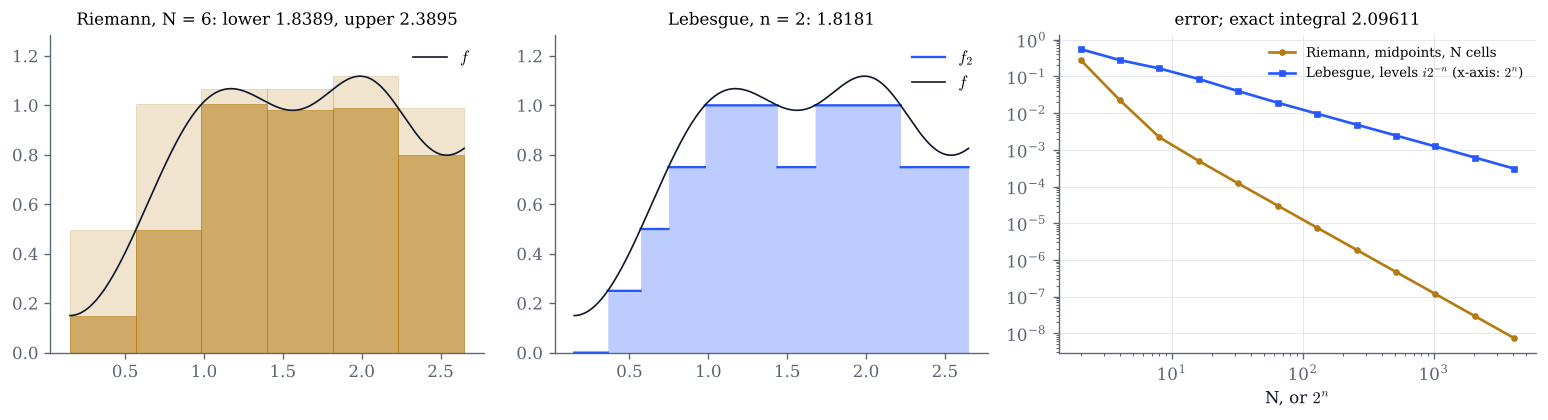

In [2]:
def wave(x):
    return 0.15 + 0.9 * np.sin(1.6 * (x - 0.15)) ** 2 + 0.95 * np.exp(-((x - 2.05) / 0.45) ** 2)

FUNCTIONS = {
    # name: (f, a, b, exact integral, exact level measure t -> m(f >= t) or None)
    "wave (as in the notes)": (wave, 0.15, 2.65, integrate.quad(wave, 0.15, 2.65)[0], None),
    "x^2 on [0, 1]": (lambda x: x**2, 0.0, 1.0, 1 / 3, lambda t: np.clip(1 - np.sqrt(np.clip(t, 0, None)), 0, 1)),
    "x^(-1/2) on (0, 1] (unbounded)": (lambda x: x**-0.5, 0.0, 1.0, 2.0, lambda t: np.minimum(1.0, t**-2.0)),
    "1 + sin(1/x) on (0, 1] (oscillating)": (lambda x: 1 + np.sin(1 / x), 0.0, 1.0,
                                             1 + math.sin(1) - special.sici(1.0)[1], None),
}


def broken(x, y):
    jumps = np.flatnonzero(np.diff(y) != 0) + 1
    return np.insert(x, jumps, np.nan), np.insert(y.astype(float), jumps, np.nan)


def sums_demo(function="wave (as in the notes)", N=6, n=2):
    f, a, b, exact, meas = FUNCTIONS[function]
    if meas is None:
        meas = level_measure_on_grid(f, a, b, 2**18)
    x = np.linspace(a, b, 20001)[1:]
    fx = f(x)
    top = min(np.max(fx), 6.0) * 1.15
    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 1, 1.1]})
    lo, up = darboux_sums(f, a + 1e-12, b, N, samples=257)
    edges = np.linspace(a, b, N + 1)
    for l, r in zip(edges[:-1], edges[1:]):
        seg = f(np.linspace(max(l, 1e-12), r, 257))
        ax1.bar(l, min(seg.max(), top), width=r - l, align="edge", color=GOLD, alpha=0.2, edgecolor=GOLD, lw=0.6)
        ax1.bar(l, seg.min(), width=r - l, align="edge", color=GOLD, alpha=0.55, edgecolor=GOLD, lw=0.6)
    ax1.plot(x, fx, color=INK, lw=1, label="$f$")
    ax1.set(ylim=(0, top), title=f"Riemann, N = {N}: lower {lo:.4f}, upper {up:.4f}")
    ax1.legend(loc="upper right")
    fn = dyadic_approximation(fx, n)
    ax2.fill_between(x, 0, np.minimum(fn, top), color=COBALT, alpha=0.3, lw=0)
    xs, ys = broken(x, fn)
    ax2.plot(xs, ys, color=COBALT, lw=1.4, label=f"$f_{{{n}}}$")
    ax2.plot(x, fx, color=INK, lw=1, label="$f$")
    ax2.set(ylim=(0, top), title=f"Lebesgue, n = {n}: {lebesgue_sum(meas, n):.4f}")
    ax2.legend(loc="upper right")
    for ax in (ax1, ax2):
        ax.grid(False)
    Ns = 2 ** np.arange(1, 13)
    ns = np.arange(1, 13)
    ax3.plot(Ns, [abs(exact - riemann_sum(f, a, b, k, "mid")) for k in Ns], color=GOLD, marker="o", ms=3,
             label="Riemann, midpoints, N cells")
    ax3.plot(2.0**ns, [abs(exact - lebesgue_sum(meas, k)) for k in ns], color=COBALT, marker="s", ms=3,
             label="Lebesgue, levels $i2^{-n}$ (x-axis: $2^n$)")
    ax3.set(xscale="log", yscale="log", xlabel="N, or $2^n$", title=f"error; exact integral {exact:.5f}")
    ax3.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

sums_demo()

In [3]:
# Explore: the number of Riemann cells N, the Lebesgue level n, and the function.
interact(sums_demo,
         function=Dropdown(options=list(FUNCTIONS), value="wave (as in the notes)", description="f"),
         N=IntSlider(value=6, min=1, max=60, continuous_update=False, description="N"),
         n=IntSlider(value=2, min=1, max=8, continuous_update=False, description="n"));

## 2. Dominated convergence: when is $\lim\int f_n=\int\lim f_n$?

Left: $f_1,\dots,f_n$ (faint) and $f_n$ (bold), with the envelope $\sup_{k\le n}|f_k|$ (gold). Dominated convergence
applies when an integrable function lies above the whole envelope. Right: the integrals $\int f_k$, against
the integral of the limit (dotted). The first two families are the worked exercises of the notes; in the others
the envelope is not integrable, and the integrals do not converge to the integral of the limit (except for
$nxe^{-nx}$, whose envelope is bounded by $1/e$).

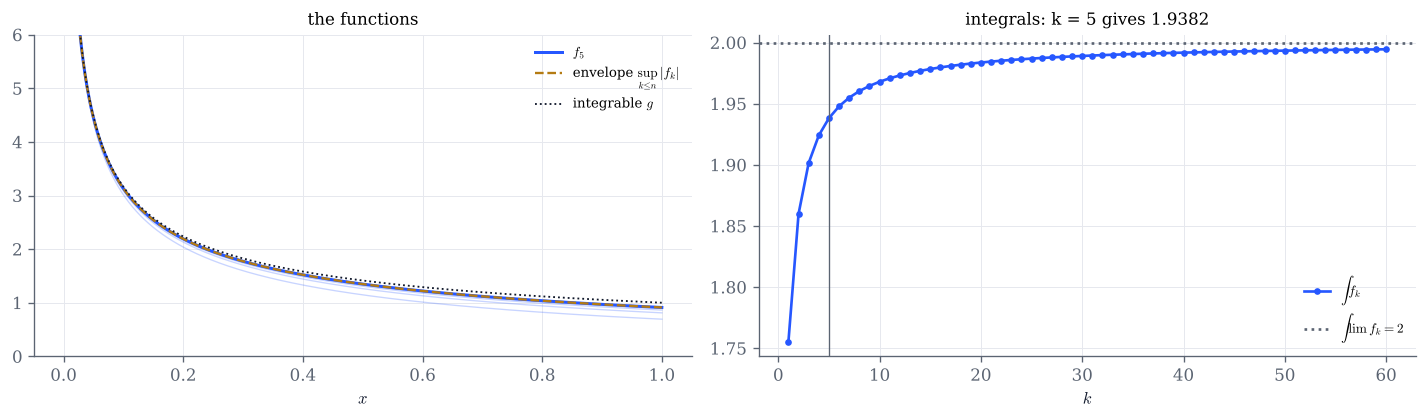

In [4]:
ks = np.arange(1, 61)
FAMILIES = {
    # name: (f(x, n), x grid, exact integral of f_n, integral of the limit, dominating g or None, axes)
    "worked exercise 1: n x^(-3/2) log(1 + x/n)": (siri_unit, np.geomspace(1e-3, 1, 1500), siri_unit_integral, 2.0,
                                                   lambda x: x**-0.5, dict(ylim=(0, 6))),
    "worked exercise 2: x^(-3/2) log(1 + x/n)": (siri_halfline, np.geomspace(1e-3, 100, 1500), siri_halfline_integral,
                                                 0.0, lambda x: siri_halfline(x, 1), dict(xscale="log", yscale="log")),
    "spike n 1(0, 1/n)": (spike, np.linspace(1e-4, 1, 3000), lambda n: np.ones_like(np.asarray(n, float)), 0.0, None,
                          dict(xscale="log")),
    "bump n^2 x e^(-nx)": (bump, np.geomspace(1e-4, 1, 1500), bump_integral, 0.0, None, dict(xscale="log")),
    "n x e^(-nx) (bounded by 1/e)": (lambda x, n: n * x * np.exp(-n * x), np.geomspace(1e-4, 1, 1500),
                                     lambda n: bump_integral(n) / np.asarray(n, float), 0.0,
                                     lambda x: np.full_like(x, 1 / math.e), dict(xscale="log", ylim=(0, 0.45))),
    "escaping block 1[n, n+1)": (escaping_block, np.linspace(0, 40, 4001), lambda n: np.ones_like(np.asarray(n, float)),
                                 0.0, None, dict(ylim=(0, 1.3))),
}


def dct_demo(family="worked exercise 1: n x^(-3/2) log(1 + x/n)", n=5):
    f, x, integral, int_lim, g, axes = FAMILIES[family]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.6))
    for k in range(1, n + 1):
        ax1.plot(x, f(x, k), color=COBALT, lw=0.8, alpha=0.25)
    ax1.plot(x, f(x, n), color=COBALT, lw=1.8, label=f"$f_{{{n}}}$")
    env = envelope(f, x, np.arange(1, n + 1))
    ax1.plot(x, env, color=GOLD, lw=1.4, ls="--", label=r"envelope $\sup_{k\leq n}|f_k|$")
    if g is not None:
        ax1.plot(x, g(x), color=INK, lw=1.1, ls=":", label="integrable $g$")
    ax1.set(xlabel="$x$", title="the functions")
    if "ylim" not in axes and axes.get("yscale") != "log":
        ax1.set_ylim(0, 1.15 * env.max())
    ax1.set(**axes)
    ax1.legend(fontsize=8, loc="upper right")
    vals = integral(ks)
    ax2.plot(ks, vals, color=COBALT, marker="o", ms=3, label=r"$\int f_k$")
    ax2.axhline(int_lim, color=GREY, ls=":", label=rf"$\int\lim f_k = {int_lim:g}$")
    ax2.axvline(n, color=GREY, lw=0.8)
    ax2.set(xlabel="$k$", title=f"integrals: k = {n} gives {float(integral(n)):.4f}")
    ax2.legend(fontsize=8)
    fig.tight_layout()
    plt.show()

dct_demo()

In [5]:
# Explore: pick a family and move n. Which families have an integrable function above the envelope?
interact(dct_demo,
         family=Dropdown(options=list(FAMILIES), value="worked exercise 1: n x^(-3/2) log(1 + x/n)", description="f_n"),
         n=IntSlider(value=5, min=1, max=60, continuous_update=False, description="n"));

## 3. A series that is not an integral

The measure of the worked exercise puts mass $2^{-n}$ at $x_n=(-1)^{n-1}2^n/n$. For $f(x)=x$ the series
$\sum_n f(x_n)\mu(\{x_n\})=\sum_n(-1)^{n-1}/n$ converges to $\log 2$, but not absolutely: $f\notin L^1(\mu)$.
Rearranging it, $p$ positive terms then $q$ negative ones, gives $\log 2+\frac12\log\frac pq$, and Riemann's greedy
rearrangement reaches any target. For the integrable $g(x)=\mathrm{sign}(x)|x|^{1/2}$ every rearrangement has the same
sum $\int g\,\mathrm d\mu$, so the greedy procedure aimed at any other target stalls short of it: it runs out of terms of one sign,
and what it builds is not a rearrangement of the whole series.

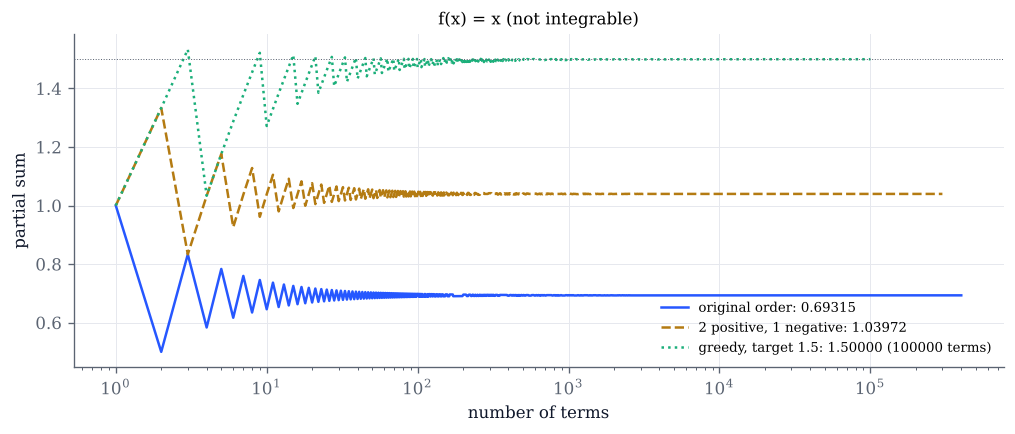

predicted limit of the (2,1) rearrangement: log 2 + log(p/q)/2 = 1.03972


In [6]:
POS, NEG = alternating_parts(200_000)
t_g = siri_discrete(1000).terms(lambda x: np.sign(x) * np.abs(x) ** 0.5)
POS_G, NEG_G = t_g[t_g > 0], t_g[t_g < 0]


def series_demo(p=2, q=1, target=1.5, function="f(x) = x (not integrable)"):
    pos, neg = (POS, NEG) if function.startswith("f") else (POS_G, NEG_G)
    original = np.cumsum(np.ravel(np.column_stack([pos[:len(neg)], neg[:len(pos)]])))
    pq = np.cumsum(rearrange_pq(pos, neg, p, q))
    greedy = np.cumsum(rearrange_to_target(pos, neg, target, 100_000))
    fig, ax = plt.subplots(figsize=(10, 3.6))
    for s, color, ls, label in [(original, COBALT, "-", f"original order: {original[-1]:.5f}"),
                                (pq, GOLD, "--", f"{p} positive, {q} negative: {pq[-1]:.5f}"),
                                (greedy, GREEN, ":", f"greedy, target {target}: {greedy[-1]:.5f} ({len(greedy)} terms)")]:
        k = np.unique(np.geomspace(1, len(s), 1200).astype(int)) - 1
        ax.plot(k + 1, s[k], color=color, ls=ls, lw=1.5, label=label)
    ax.axhline(target, color=GREY, lw=0.6, ls=":")
    ax.set(xscale="log", xlabel="number of terms", ylabel="partial sum", title=function)
    ax.legend(fontsize=8, loc="lower right")
    plt.show()
    if function.startswith("f"):
        print(f"predicted limit of the ({p},{q}) rearrangement: log 2 + log(p/q)/2 = {pq_limit(p, q):.5f}")
    else:
        print(f"int g dmu = {t_g.sum():.10f}; int g+ = {POS_G.sum():.4f}, int g- = {-NEG_G.sum():.4f}")

series_demo()

In [7]:
interact(series_demo,
         p=IntSlider(value=2, min=1, max=10, continuous_update=False, description="p"),
         q=IntSlider(value=1, min=1, max=10, continuous_update=False, description="q"),
         target=FloatSlider(value=1.5, min=-2, max=3, step=0.05, continuous_update=False, description="target"),
         function=Dropdown(options=["f(x) = x (not integrable)", "g(x) = sign(x)|x|^(1/2) (integrable)"],
                           description="function"));

## 4. $\sin x/x$: an improper integral that is not a Lebesgue integral

$\int_1^T\frac{\sin x}{x}\,\mathrm dx$ converges to $\frac\pi2-\mathrm{Si}(1)\approx0.6247$, but
$\int_1^T\frac{|\sin x|}{x}\,\mathrm dx$ grows like $\frac2\pi\log T+C$, $C\approx0.16684$, so $\frac{\sin x}{x}\notin L^1([1,\infty))$.
Both are computed exactly from the sine integral $\mathrm{Si}$. The divergence is so slow that $J(T)$ reaches
$10$ only at $T\approx5\times10^6$.

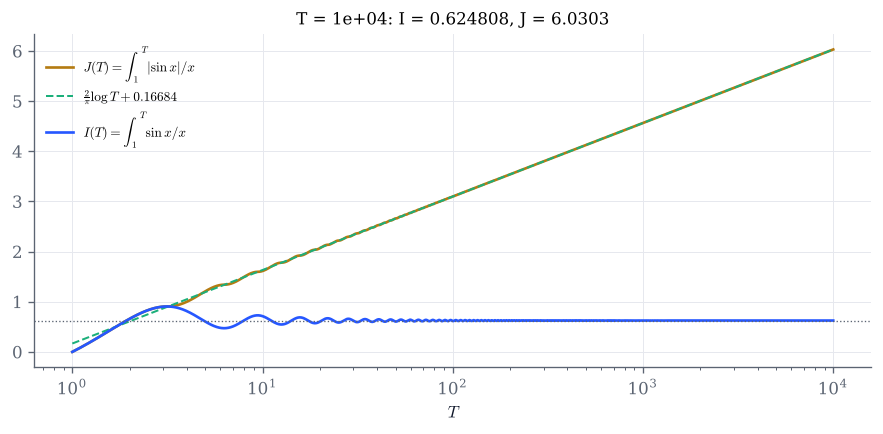

In [8]:
C = abs_sine_constant()


def sine_demo(log10_T=4.0):
    T = np.geomspace(1, 10**log10_T, 2000)
    I, J = sine_integral_from_1(T), abs_sine_integral_from_1(T)
    fig, ax = plt.subplots(figsize=(9, 3.6))
    ax.plot(T, J, color=GOLD, lw=1.6, label=r"$J(T)=\int_1^T|\sin x|/x$")
    ax.plot(T, 2 / np.pi * np.log(T) + C, color=GREEN, ls="--", lw=1.2, label=rf"$\frac{{2}}{{\pi}}\log T+{C:.5f}$")
    ax.plot(T, I, color=COBALT, lw=1.6, label=r"$I(T)=\int_1^T\sin x/x$")
    ax.axhline(SINE_LIMIT, color=GREY, ls=":", lw=0.8)
    ax.set(xscale="log", xlabel="$T$", title=f"T = {T[-1]:.3g}: I = {I[-1]:.6f}, J = {J[-1]:.4f}")
    ax.legend(fontsize=8, loc="upper left")
    plt.show()

sine_demo()

In [9]:
interact(sine_demo, log10_T=FloatSlider(value=4.0, min=0.5, max=7.0, step=0.25, continuous_update=False,
                                        description="log10 T"));

## Things to try

- In section 1, take $x^{-1/2}$ and compare the two error curves. Which term of $2-L_n=\frac1n+2^{-n-1}+\dots$ dominates, and why?
- In section 1, the oscillating $1+\sin(1/x)$ is bounded and continuous except at $0$, so it is Riemann integrable on $[0,1]$
  (Theorem 5.12, part 2). Which cells keep its upper and lower sums apart, and how fast does the gap close as $N$ grows?
- In section 2, for the spike and the bump the envelope keeps growing near $0$. Estimate $\int_\varepsilon^1$ of the envelope as $\varepsilon\to0$.
- In section 3, find $p$ and $q$ with $\log2+\frac12\log\frac pq=0$. Then switch to the integrable $g$: do the sliders still move the sum?
- In section 4, how large is $J(T)$ at $T=10^7$? Would you have guessed from the numbers alone that $J$ diverges?